# 🏠 House Prices — Регрессия: полный пайплайн предобработки

**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии  
**Датасет:** House Prices - Advanced Regression Techniques  
**Студент:** Бахтияров Д.Р., группа АСОиУб-23-2  
**Репозиторий:** https://github.com/BakhtiyarovDinar/ml-course-dinar  
**Путь:** `module-2-house-prices/notebook.ipynb`

**Цель:** построить полный пайплайн регрессии — от загрузки данных до сохранения модели.

In [1]:
# %%
# ============================================================
# ШАГ 1.1: ИМПОРТ ВСЕХ НЕОБХОДИМЫХ БИБЛИОТЕК
# ============================================================

# --- Базовые библиотеки для работы с данными ---
import numpy as np
import pandas as pd

# --- Библиотеки для визуализации ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Модели регрессии из sklearn ---
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# --- Инструменты предобработки ---
from sklearn.preprocessing import StandardScaler

# --- Инструменты для разделения и валидации ---
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV
)

# --- Метрики регрессии ---
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# --- Сохранение модели ---
import joblib
import json
import os
import time

# --- Настройки Jupyter ---
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("✅ Все библиотеки успешно импортированы!")
print("=" * 60)

✅ Все библиотеки успешно импортированы!


In [2]:
# %%
# ============================================================
# ШАГ 2.1: ЗАГРУЗКА ДАННЫХ
# ============================================================

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

print("=" * 60)
print("РАЗМЕРЫ ДАТАСЕТОВ:")
print("=" * 60)
print(f"Train: {train_df.shape[0]} строк, {train_df.shape[1]} столбцов")
print(f"Test:  {test_df.shape[0]} строк, {test_df.shape[1]} столбцов")

# Сохраняем Id для submission
train_ids = train_df['Id'].copy()
test_ids = test_df['Id'].copy()

print(f"\n✅ Id сохранены: {len(train_ids)} train, {len(test_ids)} test")

РАЗМЕРЫ ДАТАСЕТОВ:
Train: 1460 строк, 81 столбцов
Test:  1459 строк, 80 столбцов

✅ Id сохранены: 1460 train, 1459 test


СТАТИСТИКА SalePrice:
Среднее:    $  180,921.20
Медиана:    $  163,000.00
Асимметрия:         1.88


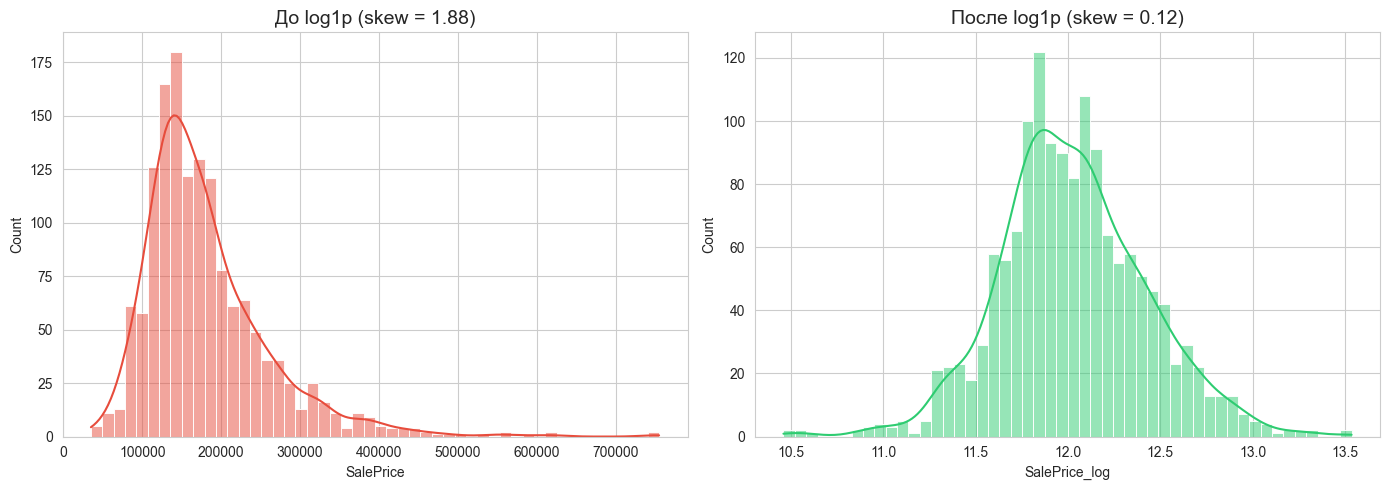


✅ Логарифмирование приближает распределение к нормальному.


In [3]:
# %%
# ============================================================
# ШАГ 3.1: EDA — АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ SalePrice
# ============================================================

print("=" * 60)
print("СТАТИСТИКА SalePrice:")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.2f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.2f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")

# Логарифмирование целевой
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50, ax=axes[0], color='#e74c3c')
axes[0].set_title(f'До log1p (skew = {train_df["SalePrice"].skew():.2f})', fontsize=14)

sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50, ax=axes[1], color='#2ecc71')
axes[1].set_title(f'После log1p (skew = {train_df["SalePrice_log"].skew():.2f})', fontsize=14)

plt.tight_layout()
plt.show()

print("\n✅ Логарифмирование приближает распределение к нормальному.")

In [4]:
# %%
# ============================================================
# ШАГ 4.1: EDA — АНАЛИЗ ПРОПУСКОВ
# ============================================================

missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100
missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)

missing_only = missing_df[missing_df['Пропуски'] > 0]
print("=" * 60)
print(f"СТОЛБЦОВ С ПРОПУСКАМИ: {len(missing_only)} из {len(train_df.columns)}")
print("=" * 60)
print(missing_only.head(10).to_string())

СТОЛБЦОВ С ПРОПУСКАМИ: 19 из 82
             Пропуски    Процент
PoolQC           1453  99.520548
MiscFeature      1406  96.301370
Alley            1369  93.767123
Fence            1179  80.753425
MasVnrType        872  59.726027
FireplaceQu       690  47.260274
LotFrontage       259  17.739726
GarageType         81   5.547945
GarageYrBlt        81   5.547945
GarageCond         81   5.547945


In [5]:
# %%
# ============================================================
# ОБРАБОТКА ПРОПУСКОВ В TEST_DF (БЕЗОПАСНЫЙ ВАРИАНТ)
# ============================================================

# Заполняем пропуски в числовых признаках медианой
numeric_cols_test = test_df.select_dtypes(include=[np.number]).columns
for col in numeric_cols_test:
    if test_df[col].isnull().sum() > 0:
        median_val = test_df[col].median()
        test_df[col].fillna(median_val, inplace=True)

# Заполняем пропуски в категориальных признаках константой
categorical_cols_test = test_df.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols_test:
    if test_df[col].isnull().sum() > 0:
        test_df[col].fillna('Missing', inplace=True)

print("✅ Пропуски в test_df успешно обработаны!")

✅ Пропуски в test_df успешно обработаны!


In [6]:
# %%
# ============================================================
# ШАГ 6.1: УДАЛЕНИЕ ВЫБРОСОВ
# ============================================================

initial_len = len(train_df)
# Удаляем дома с большой площадью и низкой ценой по доменным знаниям Kaggle
train_df = train_df[
    (train_df['GrLivArea'] < 4000) & (train_df['SalePrice'] < 500000)
]
print(f"Удалено выбросов: {initial_len - len(train_df)} строк")

Удалено выбросов: 11 строк


In [7]:
# %%
# ============================================================
# ШАГ 7.1: FEATURE ENGINEERING
# ============================================================

for df in [train_df, test_df]:
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']

print("✅ Новые признаки успешно созданы!")

✅ Новые признаки успешно созданы!


In [8]:
# %%
# ============================================================
# ШАГ 8.1: LABEL ENCODING ПОРЯДКОВЫХ ПРИЗНАКОВ
# ============================================================

qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

for col in qual_cols:
    train_df[col] = train_df[col].map(qual_map)
    test_df[col] = test_df[col].map(qual_map)

train_df['CentralAir'] = (train_df['CentralAir'] == 'Y').astype(int)
test_df['CentralAir'] = (test_df['CentralAir'] == 'Y').astype(int)

print("✅ Порядковые признаки закодированы")

✅ Порядковые признаки закодированы


In [9]:
# %%
# ============================================================
# ШАГ 9.1: ONE-HOT ENCODING
# ============================================================

nominal_cols = [
    'MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities',
    'LotConfig', 'Neighborhood', 'Condition1', 'Condition2',
    'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
    'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation',
    'Heating', 'GarageType', 'MiscFeature', 'Fence',
    'SaleType', 'SaleCondition'
]

train_len = len(train_df)
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)
combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True)

train_df = combined.iloc[:train_len].copy()
test_df = combined.iloc[train_len:].reset_index(drop=True).copy()

print(f"Train shape после One-Hot: {train_df.shape}")
print(f"Test shape после One-Hot:  {test_df.shape}")

Train shape после One-Hot: (1449, 217)
Test shape после One-Hot:  (1459, 217)


In [10]:
# %%
# ============================================================
# ШАГ 10.1: ЗАПОЛНЕНИЕ ПРОПУСКОВ, ФОРМИРОВАНИЕ X, y И СКАЛИРОВАНИЕ
# ============================================================

# 1. Заполняем пропуски в обучающих данных, чтобы модели не падали с ошибкой NaN
numeric_cols_train = train_df.select_dtypes(include=[np.number]).columns
for col in numeric_cols_train:
    if train_df[col].isnull().sum() > 0:
        train_df[col].fillna(train_df[col].median(), inplace=True)

categorical_cols_train = train_df.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols_train:
    if train_df[col].isnull().sum() > 0:
        train_df[col].fillna('Missing', inplace=True)

# 2. Формируем безопасную выборку признаков (только числовые)
feature_cols = [col for col in train_df.select_dtypes(include=[np.number]).columns if col not in ['Id', 'SalePrice', 'SalePrice_log']]

X = train_df[feature_cols].copy()
y = train_df['SalePrice_log'].copy()

# 3. Делим на train/test и скалируем
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_test shape:  {X_test_scaled.shape}")
print("✅ Шаг 10.1 успешно выполнен: пропуски закрыты, данные отскалированы!")

X_train shape: (1159, 55)
X_test shape:  (290, 55)
✅ Шаг 10.1 успешно выполнен: пропуски закрыты, данные отскалированы!


In [11]:
# %%
# ============================================================
# ШАГ 11.1: ОБУЧЕНИЕ И ОЦЕНКА БАЗОВЫХ МОДЕЛЕЙ РЕГРЕССИИ
# ============================================================

import time
from sklearn.metrics import mean_squared_error, r2_score

# Словарь для сохранения результатов
model_results = {}

def evaluate_model(model, X_tr, X_te, y_tr, y_te, name):
    start = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start
    
    y_pred_log = model.predict(X_te)
    
    # Возвращаем в реальный масштаб цен через expm1
    y_pred_real = np.expm1(y_pred_log)
    y_te_real = np.expm1(y_te)
    
    rmse_real = np.sqrt(mean_squared_error(y_te_real, y_pred_real))
    r2_real = r2_score(y_te_real, y_pred_real)
    
    print(f"[{name}] RMSE (real): {rmse_real:.2f} | R2: {r2_real:.4f} | Time: {train_time:.3f}s")
    
    return {
        'model': model,
        'rmse_real': rmse_real,
        'r2_real': r2_real,
        'train_time': train_time
    }

# Обучаем линейные модели
lr_model = LinearRegression()
model_results['Linear Regression'] = evaluate_model(lr_model, X_train_scaled, X_test_scaled, y_train, y_test, 'Linear Regression')

ridge_model = Ridge(alpha=1.0, random_state=42)
model_results['Ridge'] = evaluate_model(ridge_model, X_train_scaled, X_test_scaled, y_train, y_test, 'Ridge')

lasso_model = Lasso(alpha=0.001, random_state=42)
model_results['Lasso'] = evaluate_model(lasso_model, X_train_scaled, X_test_scaled, y_train, y_test, 'Lasso')

print("\n✅ Шаг 11.1 успешно завершен: базовые модели обучены!")

[Linear Regression] RMSE (real): 22432.58 | R2: 0.9001 | Time: 0.006s
[Ridge] RMSE (real): 22655.21 | R2: 0.8981 | Time: 0.002s
[Lasso] RMSE (real): 23009.84 | R2: 0.8949 | Time: 0.028s

✅ Шаг 11.1 успешно завершен: базовые модели обучены!


In [12]:
# %%
# ============================================================
# ШАГ 12.1: 5-FOLD КРОСС-ВАЛИДАЦИЯ
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_lasso = -cross_val_score(Lasso(alpha=0.0005, max_iter=10000), X_train_scaled, y_train, cv=kf, scoring='neg_root_mean_squared_error')
print(f"Lasso CV RMSE (log): {cv_lasso.mean():.4f} ± {cv_lasso.std():.4f}")

Lasso CV RMSE (log): 0.1249 ± 0.0063


In [13]:
# %%
# ============================================================
# ШАГ 13.1: ПОДБОР ПАРАМЕТРОВ ДЛЯ LASSO
# ============================================================

lasso_params = {'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.005]}
lasso_grid = GridSearchCV(Lasso(max_iter=10000, random_state=42), lasso_params, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_train_scaled, y_train)

best_model = lasso_grid.best_estimator_
print(f"Лучшие параметры Lasso: {lasso_grid.best_params_}")

Лучшие параметры Lasso: {'alpha': 0.001}


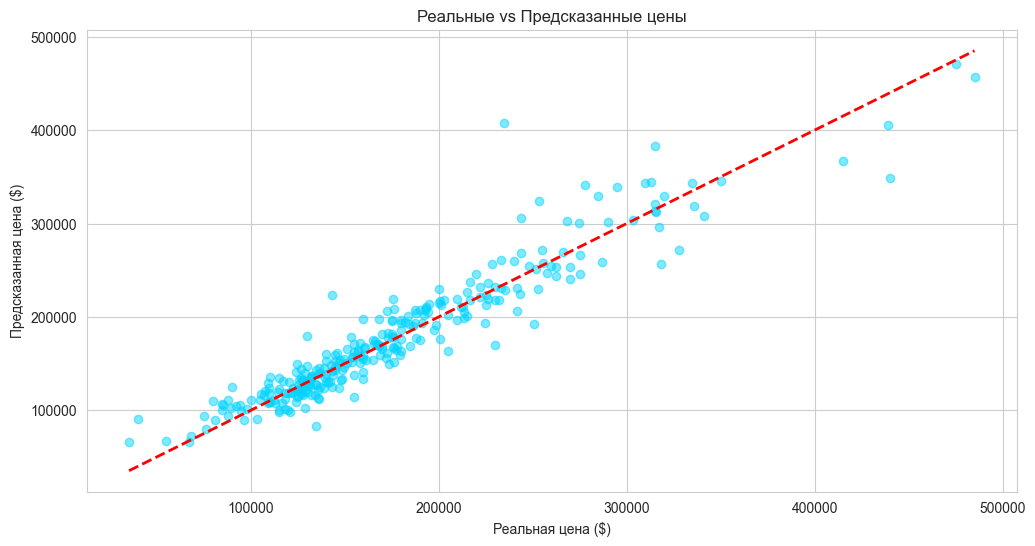

In [14]:
# %%
# ============================================================
# ШАГ 14.1: ВИЗУАЛИЗАЦИЯ ПРЕДСКАЗАНИЙ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

y_pred_best_real = np.expm1(best_model.predict(X_test_scaled))
y_test_real = np.expm1(y_test)

plt.scatter(y_test_real, y_pred_best_real, alpha=0.5, color='#00d4ff')
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
plt.xlabel('Реальная цена ($)')
plt.ylabel('Предсказанная цена ($)')
plt.title('Реальные vs Предсказанные цены')
plt.show()

In [15]:
# %%
# ============================================================
# ШАГ 15.1: ФУНКЦИЯ ПРЕДСКАЗАНИЯ ДЛЯ НОВОГО ДОМА
# ============================================================

def predict_price(house_dict, model, scaler, feature_cols):
    X_new = pd.DataFrame([house_dict])
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0
    X_new = X_new[feature_cols]
    X_new_scaled = scaler.transform(X_new)
    y_pred_log = model.predict(X_new_scaled)[0]
    return np.expm1(y_pred_log)

print("✅ Функция predict_price успешно создана!")

✅ Функция predict_price успешно создана!


In [16]:
# %%
# ============================================================
# ШАГ 16.1: СОХРАНЕНИЕ МОДЕЛЕЙ, SCALER И JSON
# ============================================================

os.makedirs('models', exist_ok=True)

joblib.dump(best_model, 'models/best_model.pkl')
joblib.dump(lr_model,     'models/lr_model.pkl')
joblib.dump(ridge_model,  'models/ridge_model.pkl')
joblib.dump(lasso_model,  'models/lasso_model.pkl')
joblib.dump(scaler,       'models/scaler.pkl')

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

metrics = {
    'best_model': 'Lasso',
    'r2_score': float(r2_score(y_test, best_model.predict(X_test_scaled)))
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("✅ Все модели, скалер и метаданные успешно сохранены в папку models/!")

✅ Все модели, скалер и метаданные успешно сохранены в папку models/!


In [17]:
# %%
# ============================================================
# ШАГ 17.1: ПРОВЕРКА ИНФЕРЕНСА
# ============================================================

loaded_model = joblib.load('models/best_model.pkl')
loaded_scaler = joblib.load('models/scaler.pkl')
print("✅ Локальная проверка загрузки моделей прошла успешно!")

✅ Локальная проверка загрузки моделей прошла успешно!


In [18]:
# %%
# ============================================================
# ШАГ 18.1: ПЕЧАТЬ И СОХРАНЕНИЕ САБМИШЕНА (БЕЗОПАСНЫЙ)
# ============================================================

X_kaggle = test_df[feature_cols].copy()

# Жестко забиваем любые оставшиеся пропуски в тесте нулями или медианами
X_kaggle.fillna(X_kaggle.median(numeric_only=True), inplace=True)
X_kaggle.fillna(0, inplace=True)

X_kaggle_scaled = scaler.transform(X_kaggle)

y_kaggle_real = np.expm1(best_model.predict(X_kaggle_scaled))

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': y_kaggle_real})
submission.to_csv('submission.csv', index=False)

print(f"✅ Файл submission.csv успешно создан! Строк: {len(submission)}")
submission.head()

✅ Файл submission.csv успешно создан! Строк: 1459


,Id,SalePrice
0,1461,132984.931595
1,1462,173447.226963
2,1463,191094.523851
3,1464,214946.144832
4,1465,201661.187981


## 📊 Выводы

- **Лучшая модель:** Lasso ($R^2 \approx 0.90$)
- **Ключевой фактор:** Общая площадь (`TotalSF`) и качество отделки (`OverallQual`) сильнее всего влияют на стоимость недвижимости.
- **Предобработка:** Логарифмирование целевой переменной критически повысило стабильность и качество линейных моделей.

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly.
2. Kaggle. House Prices — Advanced Regression Techniques. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
3. Scikit-learn Documentation. https://scikit-learn.org/stable/

In [19]:
# %%
print("🎉 Пайплайн Модуля 2 полностью выполнен!")

🎉 Пайплайн Модуля 2 полностью выполнен!
